<a href="https://colab.research.google.com/github/202343500268-NaufalDaniswara/202343500268-Machine-Learning/blob/main/BAB10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

In [2]:
rng = np.random.default_rng(42)
n = 300
X = np.vstack([
    rng.normal([5, 200000], [1.5, 30000], (100, 2)),
    rng.normal([15, 800000], [2, 50000], (100, 2)),
    rng.normal([2, 50000], [0.8, 15000], (100, 2)),
])


In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)  # Scaling WAJIB karena K-Means berbasis jarak

In [4]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
labels_kmeans = kmeans.fit_predict(X_scaled)

agglo = AgglomerativeClustering(n_clusters=3, linkage="ward")
labels_agglo = agglo.fit_predict(X_scaled)

dbscan = DBSCAN(eps=0.3, min_samples=5)
labels_dbscan = dbscan.fit_predict(X_scaled)

In [5]:
print("Silhouette Score K-Means      :", round(silhouette_score(X_scaled, labels_kmeans), 3))
print("Silhouette Score Agglomerative:", round(silhouette_score(X_scaled, labels_agglo), 3))
n_noise = (labels_dbscan == -1).sum()
print("Jumlah noise point (DBSCAN)   :", n_noise)

Silhouette Score K-Means      : 0.711
Silhouette Score Agglomerative: 0.709
Jumlah noise point (DBSCAN)   : 0


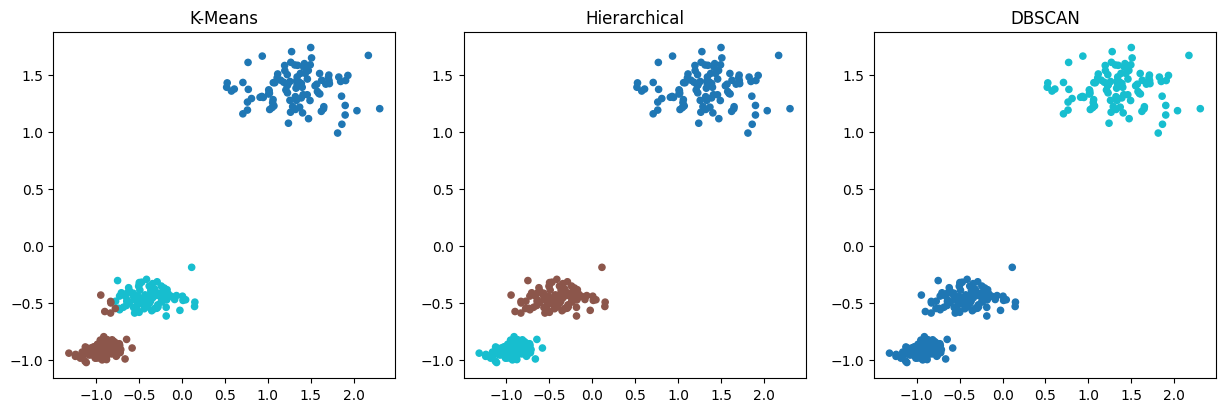

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, labels, judul in zip(axes,
                             [labels_kmeans, labels_agglo, labels_dbscan],
                             ["K-Means", "Hierarchical", "DBSCAN"]):
    ax.scatter(X_scaled[:, 0], X_scaled[:, 1], c=labels, cmap="tab10", s=20)
    ax.set_title(judul)
plt.show()